In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Blacksheep Labs: Libraries loaded!")

Blacksheep Labs: Libraries loaded!


In [2]:
# Load the diamonds dataset
df = sns.load_dataset("diamonds")

# Display the first 5 rows
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
# Check the dataset's size
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

# Display summary statistics
print("\nSummary Statistics:")
display(df.describe())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (53940, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB

Summary Statistics:


,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000



Missing Values:
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


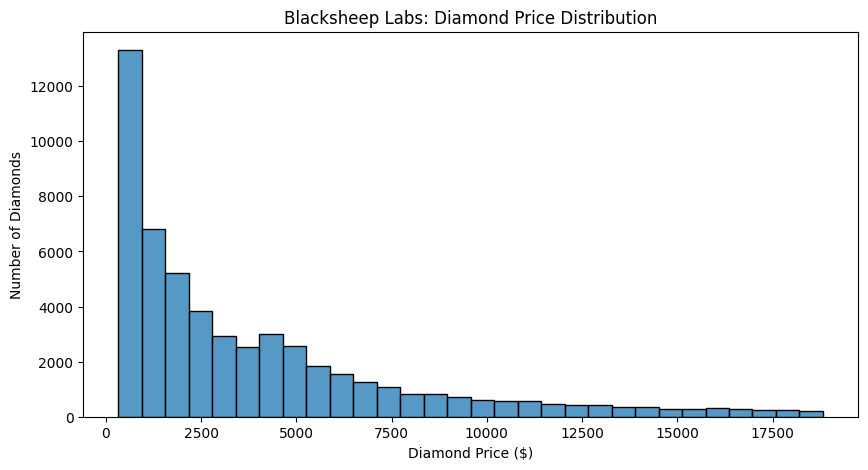

In [4]:
# Explore the distribution of diamond prices

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="price", bins=30)

plt.title("Blacksheep Labs: Diamond Price Distribution")
plt.xlabel("Diamond Price ($)")
plt.ylabel("Number of Diamonds")

plt.show()

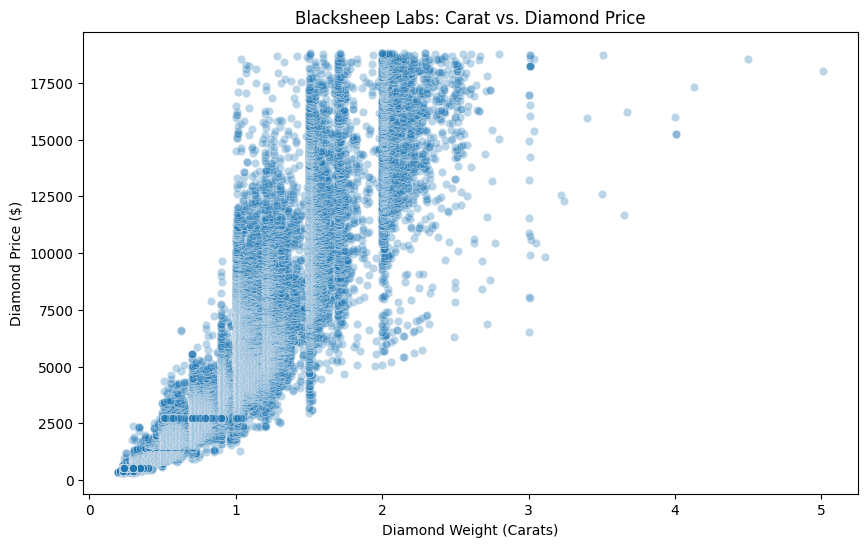

In [5]:
# Explore the relationship between carat and price

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="carat",
    y="price",
    alpha=0.3
)

plt.title("Blacksheep Labs: Carat vs. Diamond Price")
plt.xlabel("Diamond Weight (Carats)")
plt.ylabel("Diamond Price ($)")

plt.show()

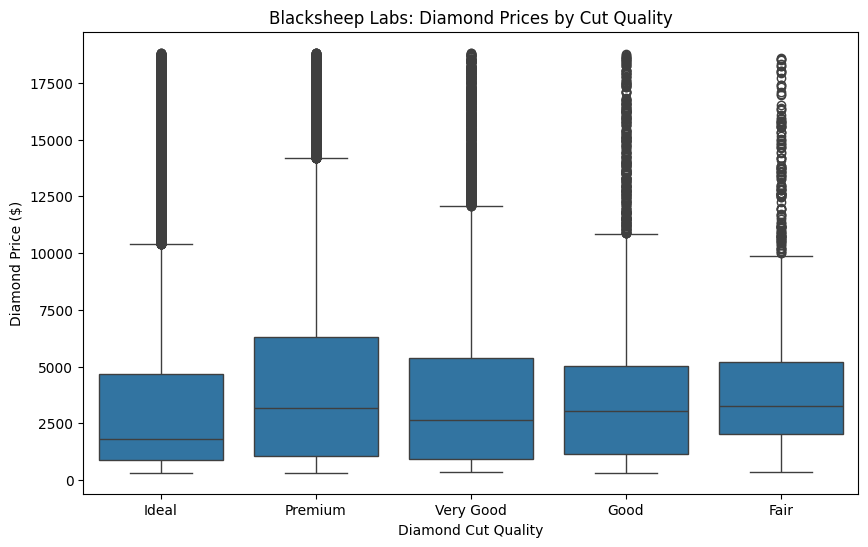

In [6]:
# Compare diamond prices by cut quality

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="cut",
    y="price"
)

plt.title("Blacksheep Labs: Diamond Prices by Cut Quality")
plt.xlabel("Diamond Cut Quality")
plt.ylabel("Diamond Price ($)")

plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# X = Input feature
X = df[["carat"]]

# y = Target variable
y = df["price"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training diamonds:", len(X_train))
print("Testing diamonds:", len(X_test))

Training diamonds: 43152
Testing diamonds: 10788


In [8]:
# Create our Linear Regression model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

# Display the slope and intercept
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

print("Blacksheep Labs: Model trained successfully!")

Slope: 7768.910490360821
Intercept: -2261.9117456492177
Blacksheep Labs: Model trained successfully!


In [9]:
# Predict diamond prices using testing data
y_pred = model.predict(X_test)

# Compare actual prices with predicted prices
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

# Display the first 10 predictions
print("Blacksheep Labs: Diamond Price Predictions")
display(results.head(10))

Blacksheep Labs: Diamond Price Predictions


,Actual Price,Predicted Price
0,559,-397.373228
1,2201,2244.056339
2,1238,845.652450
3,1304,1078.719765
4,6901,9779.899514
5,3011,5506.998745
6,1765,1700.232604
7,1679,1777.921709
8,2102,2554.812758
9,4789,6594.646213


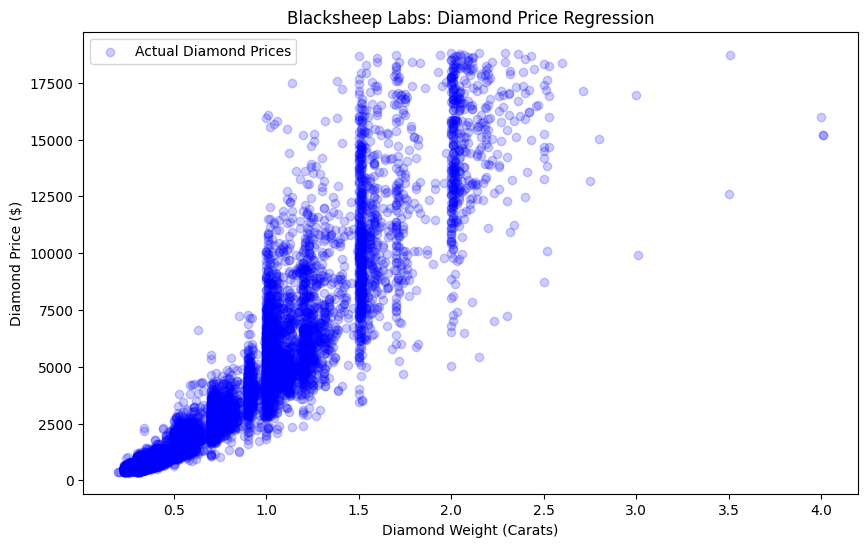

In [10]:
# Plot actual diamond prices from our test data

plt.figure(figsize=(10, 6))

plt.scatter(
    X_test["carat"],
    y_test,
    alpha=0.2,
    color="blue",
    label="Actual Diamond Prices"
)

plt.title("Blacksheep Labs: Diamond Price Regression")
plt.xlabel("Diamond Weight (Carats)")
plt.ylabel("Diamond Price ($)")
plt.legend()

plt.show()

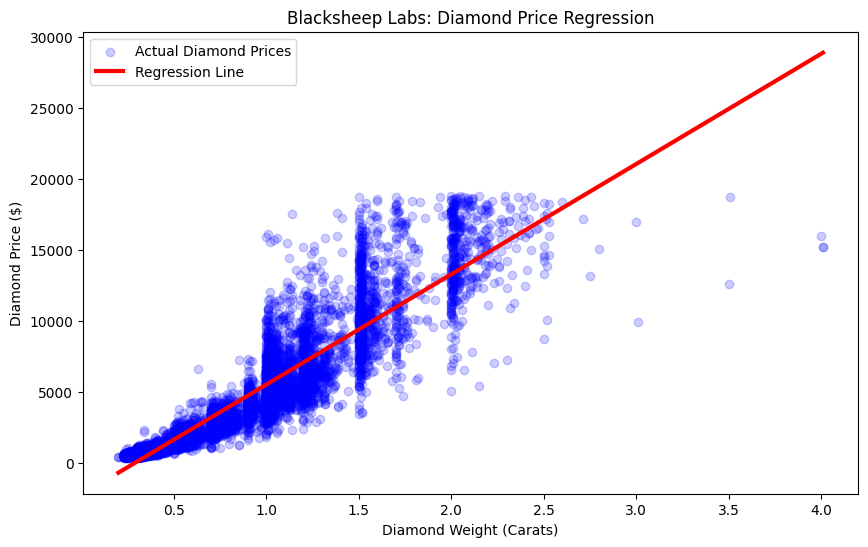

In [11]:
# Sort diamond weights so the line draws correctly
X_sorted = X_test.sort_values("carat")

# Predict prices for the sorted weights
y_sorted_pred = model.predict(X_sorted)

# Plot actual diamond prices
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test["carat"],
    y_test,
    alpha=0.2,
    color="blue",
    label="Actual Diamond Prices"
)

# Add the regression line
plt.plot(
    X_sorted["carat"],
    y_sorted_pred,
    color="red",
    linewidth=3,
    label="Regression Line"
)

plt.title("Blacksheep Labs: Diamond Price Regression")
plt.xlabel("Diamond Weight (Carats)")
plt.ylabel("Diamond Price ($)")
plt.legend()

plt.show()

In [12]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Make predictions using our test data
y_pred = model.predict(X_test)

# Calculate regression statistics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Blacksheep Labs: Regression Results")
print(f"MAE: ${mae:,.2f}")
print(f"MSE: {mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R-squared: {r2:.4f}")

Blacksheep Labs: Regression Results
MAE: $1,009.50
MSE: 2,401,388.65
RMSE: $1,549.64
R-squared: 0.8489


In [13]:
# Convert diamond cut categories into dummy variables
cut_dummies = pd.get_dummies(
    df["cut"],
    drop_first=True,
    dtype=int
)

# Display the first five rows
cut_dummies.head()

,Premium,Very Good,Good,Fair
0,0,0,0,0
1,1,0,0,0
2,0,0,1,0
3,1,0,0,0
4,0,0,1,0


In [14]:
# Combine carat weight with dummy variables
X_multi = pd.concat(
    [df[["carat"]], cut_dummies],
    axis=1
)

# Diamond price is our target
y_multi = df["price"]

# Split into training and testing data
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,
    y_multi,
    test_size=0.2,
    random_state=42
)

# Create and train our regression model
multi_model = LinearRegression()
multi_model.fit(X_train_multi, y_train_multi)

print("Model trained successfully!")
print("Features:", X_multi.columns.tolist())

Model trained successfully!
Features: ['carat', 'Premium', 'Very Good', 'Good', 'Fair']


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict diamond prices
y_pred_multi = multi_model.predict(X_test_multi)

# Calculate regression metrics
mae_multi = mean_absolute_error(y_test_multi, y_pred_multi)
mse_multi = mean_squared_error(y_test_multi, y_pred_multi)
rmse_multi = np.sqrt(mse_multi)
r2_multi = r2_score(y_test_multi, y_pred_multi)

# Display results
print(f"MAE: ${mae_multi:,.2f}")
print(f"MSE: {mse_multi:,.2f}")
print(f"RMSE: ${rmse_multi:,.2f}")
print(f"R² Score: {r2_multi:.4f}")

MAE: $990.88
MSE: 2,291,484.85
RMSE: $1,513.77
R² Score: 0.8559


In [16]:
# Display the regression intercept
print("Intercept:", multi_model.intercept_)

# Display the regression coefficients
print("\nRegression Coefficients:")

for feature, coefficient in zip(
    X_multi.columns,
    multi_model.coef_
):
    print(f"{feature}: ${coefficient:,.2f}")

Intercept: -2078.214649446474

Regression Coefficients:
carat: $7,886.68
Premium: $-374.32
Very Good: $-295.74
Good: $-688.45
Fair: $-1,807.78


In [17]:
# Create a function to display regression coefficients
def show_coefficients(model, features):

    print(f"Intercept: ${model.intercept_:,.2f}")
    print("\nRegression Coefficients:")

    for feature, coefficient in zip(
        features,
        model.coef_
    ):
        print(f"{feature}: ${coefficient:,.2f}")


# Call our function
show_coefficients(multi_model, X_multi.columns)

Intercept: $-2,078.21

Regression Coefficients:
carat: $7,886.68
Premium: $-374.32
Very Good: $-295.74
Good: $-688.45
Fair: $-1,807.78


In [18]:
# Create a function to interpret coefficients
def interpret_coefficients(model, features):

    for feature, coefficient in zip(
        features,
        model.coef_
    ):

        if coefficient > 0:
            direction = "increases"
        elif coefficient < 0:
            direction = "decreases"
        else:
            direction = "does not change"

        print(
            f"{feature}: {direction} predicted price "
            f"by ${abs(coefficient):,.2f}"
        )


# Run our function
interpret_coefficients(multi_model, X_multi.columns)

carat: increases predicted price by $7,886.68
Premium: decreases predicted price by $374.32
Very Good: decreases predicted price by $295.74
Good: decreases predicted price by $688.45
Fair: decreases predicted price by $1,807.78


In [19]:
# Select our categorical variables
categorical_features = df[["cut", "color", "clarity"]]

# Convert categories into dummy variables
categorical_dummies = pd.get_dummies(
    categorical_features,
    drop_first=True,
    dtype=int
)

# Display the first five rows
categorical_dummies.head()

,cut_Premium,cut_Very Good,cut_Good,cut_Fair,color_E,color_F,color_G,color_H,color_I,color_J,clarity_VVS1,clarity_VVS2,clarity_VS1,clarity_VS2,clarity_SI1,clarity_SI2,clarity_I1
0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
2,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0
3,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0
4,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0


In [20]:
# Combine carat with our categorical dummy variables
X_full = pd.concat(
    [df[["carat"]], categorical_dummies],
    axis=1
)

# Our target variable
y_full = df["price"]

# Split our data into training and testing sets
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42
)

# Create and train our upgraded model
full_model = LinearRegression()
full_model.fit(X_train_full, y_train_full)

print("Blacksheep Labs upgraded model trained successfully!")
print("Total features:", X_full.shape[1])

Blacksheep Labs upgraded model trained successfully!
Total features: 18


In [21]:
# Predict diamond prices using our upgraded model
y_pred_full = full_model.predict(X_test_full)

# Calculate model performance
mae_full = mean_absolute_error(y_test_full, y_pred_full)
mse_full = mean_squared_error(y_test_full, y_pred_full)
rmse_full = np.sqrt(mse_full)
r2_full = r2_score(y_test_full, y_pred_full)

# Display results
print(f"MAE: ${mae_full:,.2f}")
print(f"MSE: {mse_full:,.2f}")
print(f"RMSE: ${rmse_full:,.2f}")
print(f"R² Score: {r2_full:.4f}")

MAE: $802.12
MSE: 1,346,335.59
RMSE: $1,160.32
R² Score: 0.9153


In [22]:
# Predict prices for our training diamonds
y_train_pred = full_model.predict(X_train_full)

# Predict prices for our testing diamonds
y_test_pred = full_model.predict(X_test_full)

print("Training predictions created!")
print("Testing predictions created!")

Training predictions created!
Testing predictions created!


In [23]:
# Calculate training R²
train_r2 = r2_score(y_train_full, y_train_pred)

# Calculate testing R²
test_r2 = r2_score(y_test_full, y_test_pred)

# Display our results
print(f"Training R²: {train_r2:.4f}")
print(f"Testing R²: {test_r2:.4f}")

# Calculate the difference
gap = train_r2 - test_r2

print(f"R² Difference: {gap:.4f}")

Training R²: 0.9161
Testing R²: 0.9153
R² Difference: 0.0008


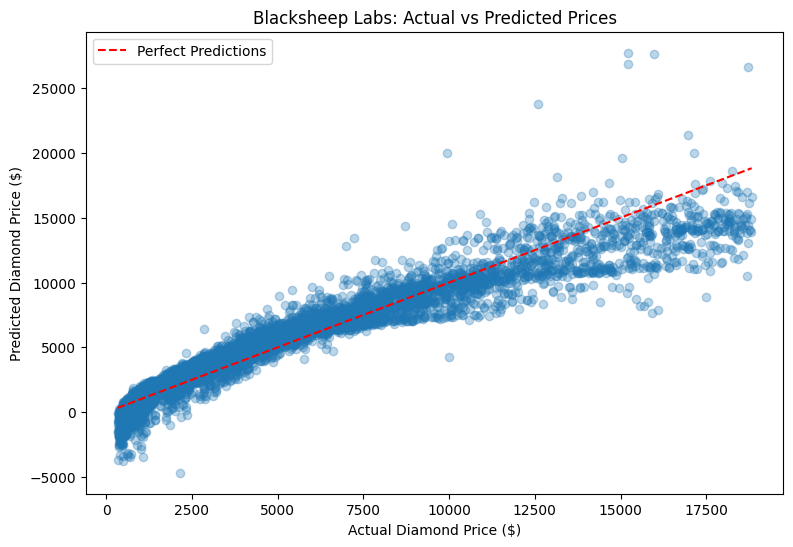

In [24]:
import matplotlib.pyplot as plt

# Plot actual vs predicted diamond prices
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test_full,
    y_test_pred,
    alpha=0.3
)

# Perfect prediction reference line
plt.plot(
    [y_test_full.min(), y_test_full.max()],
    [y_test_full.min(), y_test_full.max()],
    color="red",
    linestyle="--",
    label="Perfect Predictions"
)

plt.xlabel("Actual Diamond Price ($)")
plt.ylabel("Predicted Diamond Price ($)")
plt.title("Blacksheep Labs: Actual vs Predicted Prices")
plt.legend()
plt.show()

In [25]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Evaluate our diamond pricing model
mae = mean_absolute_error(y_test_full, y_test_pred)
mse = mean_squared_error(y_test_full, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_full, y_test_pred)

# Display results
print(f"MAE: ${mae:,.2f}")
print(f"MSE: {mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²: {r2:.4f}")

MAE: $802.12
MSE: 1,346,335.59
RMSE: $1,160.32
R²: 0.9153


In [26]:
# Calculate training error
train_mae = mean_absolute_error(
    y_train_full,
    y_train_pred
)

# Calculate testing error
test_mae = mean_absolute_error(
    y_test_full,
    y_test_pred
)

# Compare errors
mae_gap = test_mae - train_mae

print(f"Training MAE: ${train_mae:,.2f}")
print(f"Testing MAE: ${test_mae:,.2f}")
print(f"MAE Difference: ${mae_gap:,.2f}")

Training MAE: $805.79
Testing MAE: $802.12
MAE Difference: $-3.67


In [27]:
# Blacksheep Labs regression performance report

report = pd.DataFrame({
    "Metric": [
        "Training MAE",
        "Testing MAE",
        "Testing MSE",
        "Testing RMSE",
        "Training R²",
        "Testing R²"
    ],
    "Value": [
        train_mae,
        test_mae,
        mse,
        rmse,
        train_r2,
        test_r2
    ]
})

# Display the final report
print("BLACKSHEEP LABS")
print("Diamond Pricing Model Performance Report")
print("-" * 45)

display(report.round(4))

BLACKSHEEP LABS
Diamond Pricing Model Performance Report
---------------------------------------------


,Metric,Value
0,Training MAE,8.057866e+02
1,Testing MAE,8.021159e+02
2,Testing MSE,1.346336e+06
3,Testing RMSE,1.160317e+03
4,Training R²,9.161000e-01
5,Testing R²,9.153000e-01
